# 21 — EDA Panel Lémanique 2023

Sur les waypoints voiture produits par l'étape 01 (`DATA_SOURCE = "pl23"`) :

1. distributions de la précision GPS, de la vitesse utilisée, de l'intervalle et de la distance au point précédent ;
2. stationnement déclaré au domicile et au travail (`space_home`, `space_work`), joint depuis le questionnaire PL23.

La logique est dans `src/parking_search_prediction/pl23_eda.py` (et `pl23_survey.py` pour la dérivation des variables de stationnement, identique à l'étape 23). Équivalent en ligne de commande : `python scripts/21_eda_panel_lemanique.py`.

In [9]:
CONFIG_NAME = "full_waypoints.yaml"
OUTPUT_DIR = "outputs/pl23"   # sorties de l'étape 01 pour le PL23
USER_ID_MAP_FILE = "Data/GPS/pl23/20241120_dump_situee/241120_user_statistics.csv"
SURVEY_FILE = "Data/GPS/pl23/EPFL_vague1_v4.csv"

In [10]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from parking_search_prediction.config import load_config
from parking_search_prediction.pl23_eda import run_pl23_eda

config = load_config(PROJECT_ROOT / "config" / CONFIG_NAME)
config["paths"]["output_dir"] = OUTPUT_DIR
config["leg_matching"]["user_id_map"] = {
    "file": USER_ID_MAP_FILE, "legs_id_col": "user_id_fors", "waypoints_id_col": "user_id_motiontag",
}
config.setdefault("pl23_survey", {})["survey_file"] = SURVEY_FILE

In [11]:
summary = run_pl23_eda(config)
pd.DataFrame(summary["waypoint_distributions"]).T

,column,unit,n,missing,mean,median_approx,p90_approx,share_above_range
accuracy,accuracy,m,33939584,0,10.347824,5.375828,None,0.198603
speed,speed_kmh,km/h,33939584,0,44.738082,39.699586,101.031743,0.0
interval,dt_seconds,s,33863485,76099,2.409058,1.611817,5.666871,0.001903
distance,distance_from_previous_m,m,33863485,76099,27.224064,12.853819,50.662114,0.007464


## Distributions des waypoints voiture

Intervalle et distance au point précédent : le premier point de chaque leg est exclu (son point précédent appartient à un autre déplacement). Les valeurs au-delà de l'axe sont indiquées dans chaque panneau.

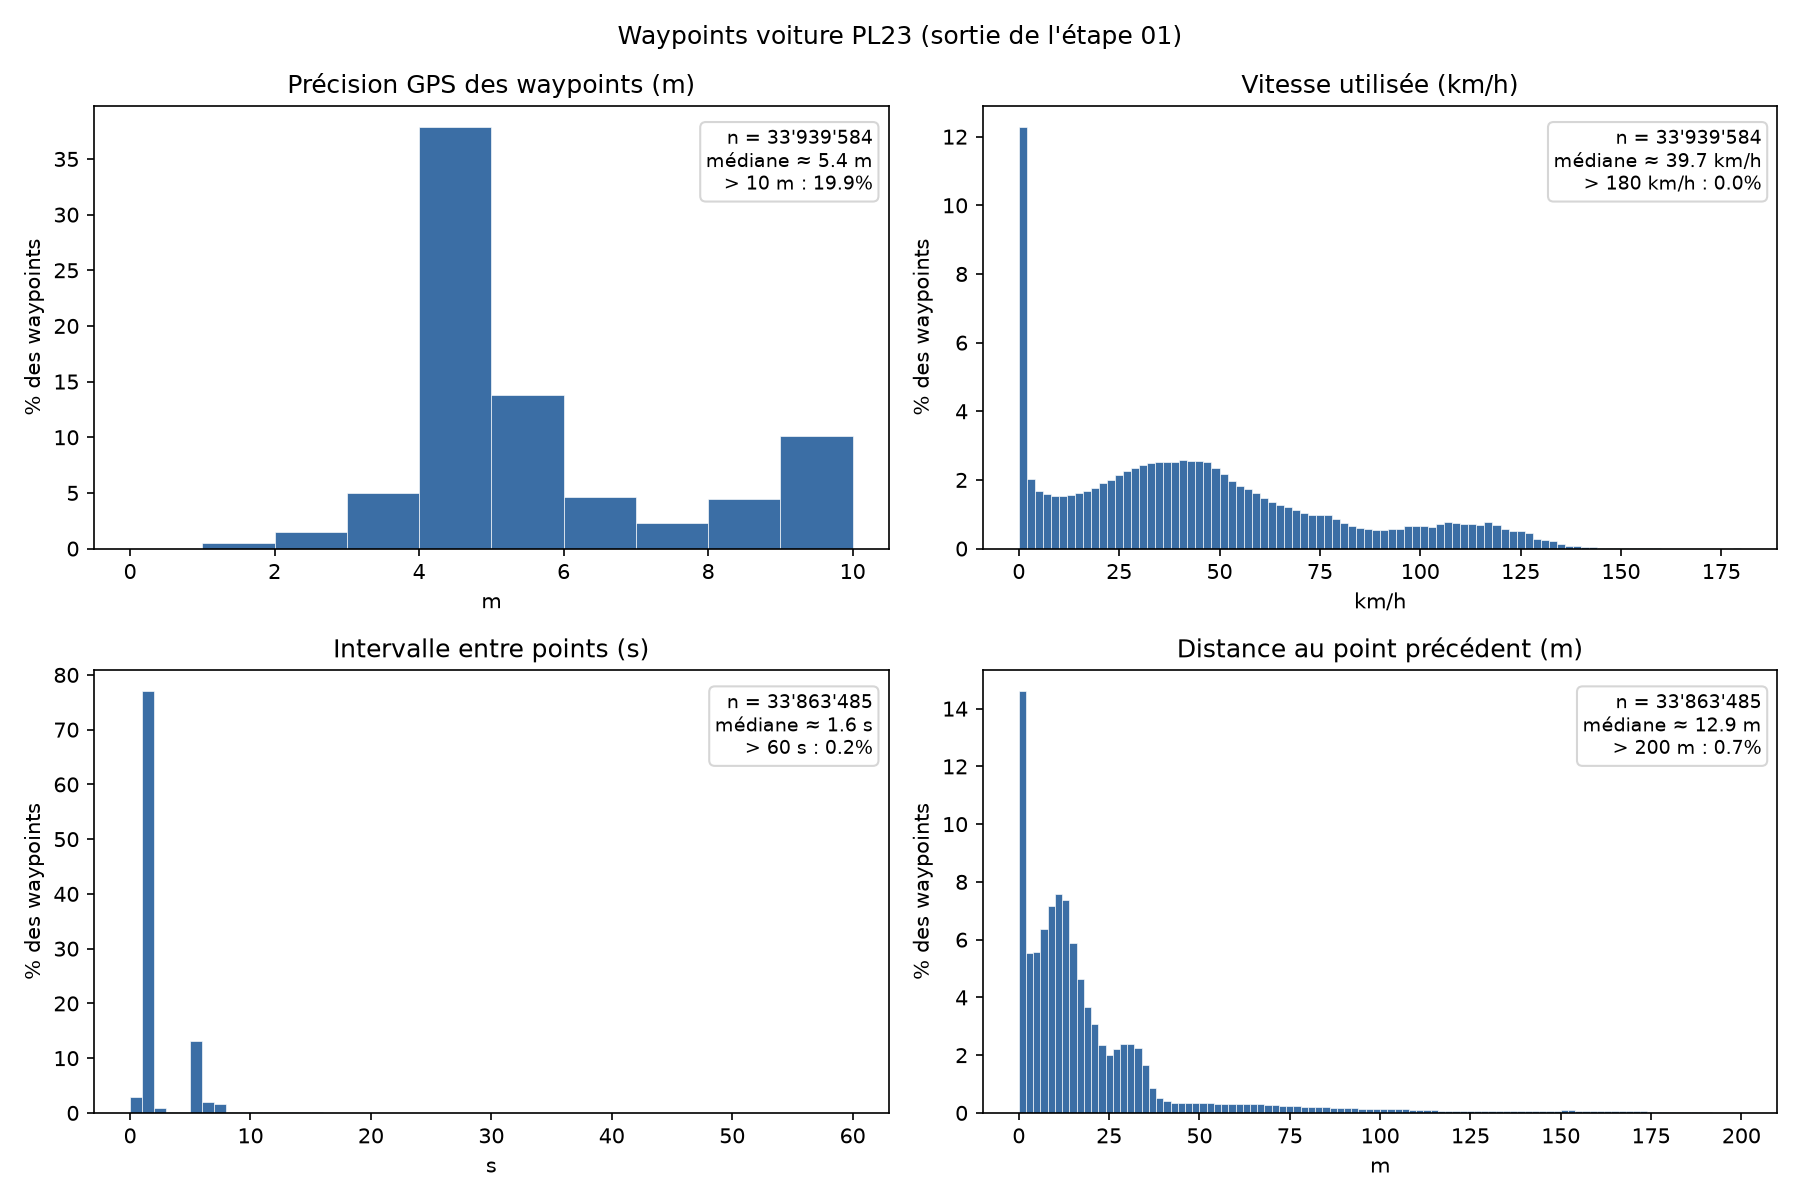

In [12]:
display(Image(filename=summary["figures"]["distributions"]))

## Stationnement déclaré au domicile et au travail

Une observation = un participant ayant des waypoints voiture. Parts calculées parmi les participants classés dans l'une des trois catégories ; les autres (`Aucun` au domicile, non renseigné, absent du questionnaire) sont comptés à part.

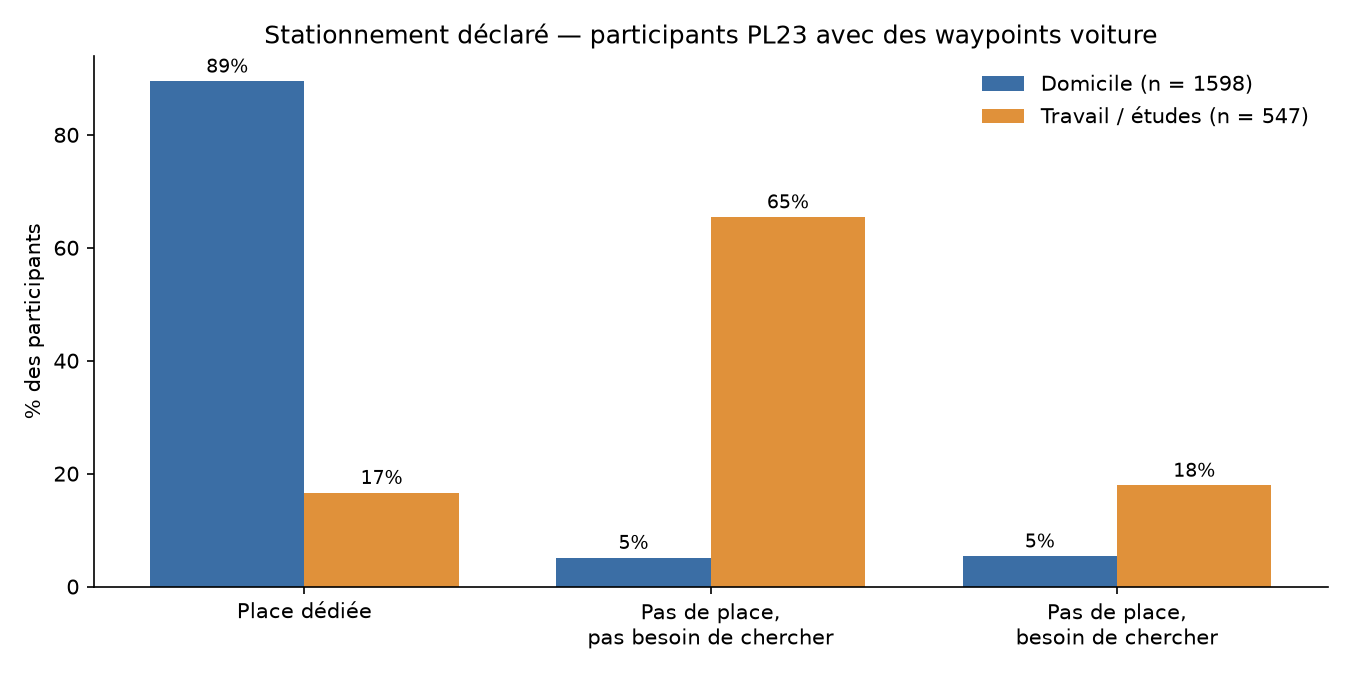

,space_home,participants
0,Place dédiée,1430
1,Aucun,276
2,"Pas de place dédiée, besoin de cruise",86
3,"Pas de place dédiée, pas besoin de cruise",82
4,nan,2


,space_work,participants
0,<NA>,1327
1,"Pas de place dédiée, pas besoin de cruise",358
2,"Pas de place dédiée, besoin de cruise",98
3,Place dédiée,91
4,nan,2


users_with_car_waypoints    1876
users_mapped_to_panel_id    1876
users_in_survey             1874
dtype: int64

In [13]:
display(Image(filename=summary["figures"]["parking_shares"]))
display(pd.DataFrame(summary["space_home_counts"].items(), columns=["space_home", "participants"]))
display(pd.DataFrame(summary["space_work_counts"].items(), columns=["space_work", "participants"]))
pd.Series({k: summary[k] for k in ["users_with_car_waypoints", "users_mapped_to_panel_id", "users_in_survey"]})

## Corpus commun de legs : effet de chaque filtre

Le corpus commun (`legs/corpus_by_leg.parquet`, construit à l'étape 01) est la base de legs **des deux méthodes**, temporelle (32) et spatiale (22). Ses filtres sont dans la section `leg_filters` du YAML. Ce panneau montre, pour chaque filtre, le **nombre de legs du corpus** selon sa valeur, les autres filtres restant à leur valeur du YAML (tirets : valeur actuelle). Il sert à choisir les valeurs **avant** de lancer les méthodes.

- Les filtres de legs sont recalculés à partir des statistiques du corpus : immédiat.
- La précision GPS (`max_accuracy_m`) est recalculée à partir des waypoints voiture (quelques minutes sur le jeu complet) ; seuls des seuils **plus stricts** que celui de l'étape 01 peuvent être testés, les points au-delà ayant déjà été retirés.
- Après avoir changé une valeur dans le YAML, relancer l'étape 01 (`FORCE_RERUN = True`) pour reconstruire le corpus.

In [14]:
import matplotlib.pyplot as plt
from parking_search_prediction.leg_corpus import (
    corpus_summary, load_corpus, plot_segments_per_leg, plot_sensitivity, segments_per_leg, sensitivity,
)

corpus = load_corpus(config)
display(pd.Series(config.get("leg_filters", {}), name="leg_filters (YAML)").to_frame())
summary = corpus_summary(corpus)
display(pd.Series(summary["status_counts"], name="corpus_status"))
pd.Series(summary["first_exclusion_reason"], name="premier filtre non vérifié (legs exclues)")

,leg_filters (YAML)
max_accuracy_m,10
min_leg_points,20
min_leg_duration_s,300
min_leg_length_m,500
min_origin_destination_distance_m,100
max_window_gap_s,120
max_trip_duration_s,18000
destination_window_radius_m,1000
exclude_tunnel_h3_destinations,True
tunnel_h3_resolution,8


not_car_leg           465516
outside_study_area    116215
in_corpus              55083
excluded               21016
no_car_waypoints        1370
Name: corpus_status, dtype: int64

leg_too_short_duration          13304
window_gap_too_long              2936
too_few_points                   2289
destination_in_tunnel_h3          893
origin_destination_too_close      796
trip_too_long                     747
leg_too_short_length               51
Name: premier filtre non vérifié (legs exclues), dtype: int64

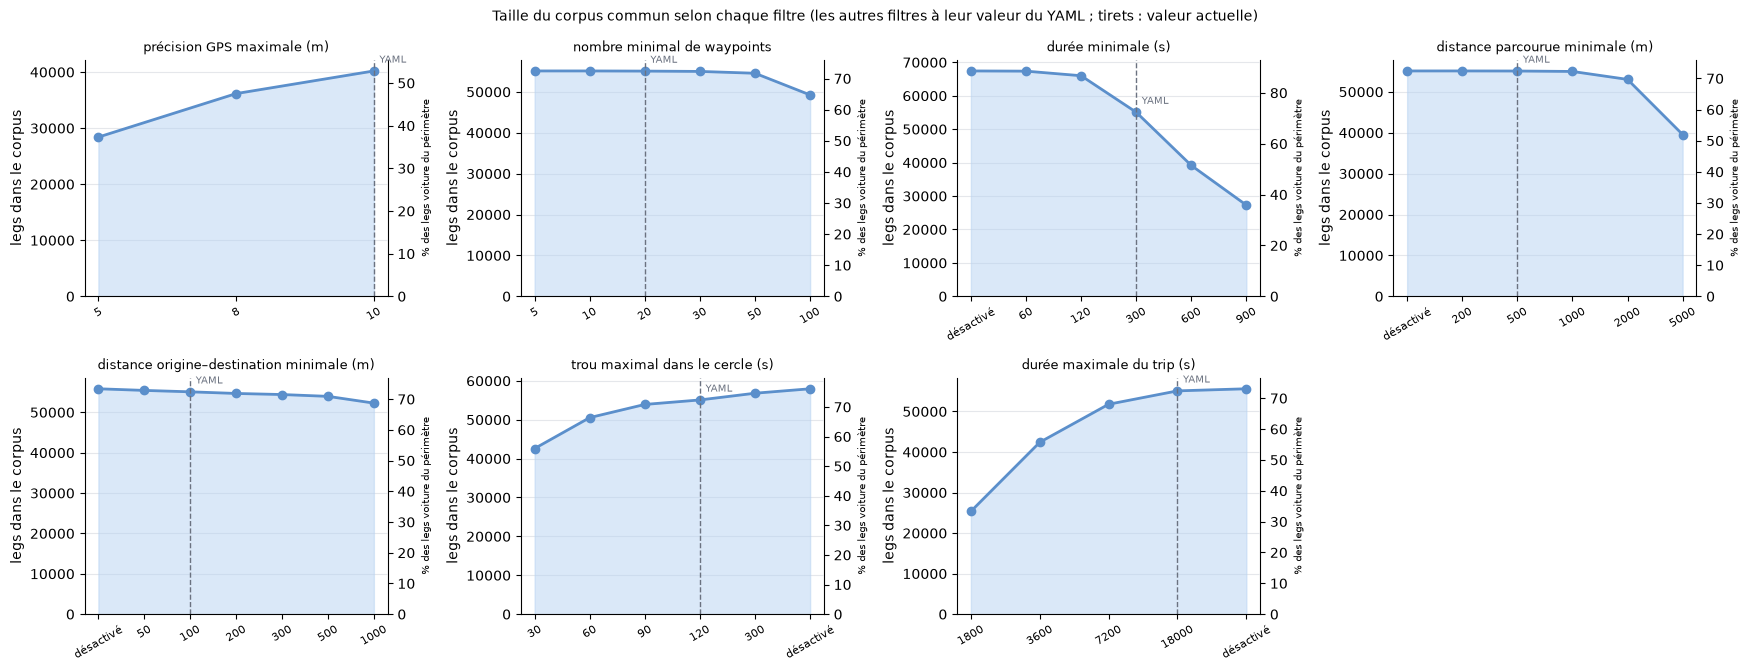

,parametre,valeur,valeur_actuelle,legs_corpus,part_corpus
0,max_accuracy_m,5.0,10,28405,0.373264
1,max_accuracy_m,8.0,10,36164,0.475223
2,max_accuracy_m,10.0,10,40204,0.528312
3,min_leg_points,5.0,20,55121,0.724333
4,min_leg_points,10.0,20,55119,0.724306
5,min_leg_points,20.0,20,55083,0.723833
6,min_leg_points,30.0,20,55004,0.722795
7,min_leg_points,50.0,20,54556,0.716908
8,min_leg_points,100.0,20,49252,0.647210
9,min_leg_duration_s,NaN,300,67424,0.886004


In [15]:
# Valeurs testées pour chaque filtre (retirer une ligne pour ne pas la calculer ; None = filtre désactivé)
SWEEPS = {
    "max_accuracy_m": [5,8,10],
    "min_leg_points": [5, 10, 20, 30, 50, 100],
    "min_leg_duration_s": [None, 60, 120, 300, 600, 900],
    "min_leg_length_m": [None, 200, 500, 1000, 2000, 5000],
    "min_origin_destination_distance_m": [None, 50, 100, 200, 300, 500, 1000],
    "max_window_gap_s": [30, 60, 90, 120, 300, None],
    "max_trip_duration_s": [1800, 3600, 7200, 18000, None],
}

sensitivity_table = sensitivity(config, SWEEPS)
fig = plot_sensitivity(sensitivity_table)
fig.savefig(Path(config["_project_root"]) / OUTPUT_DIR / "figures" / "21_corpus_sensitivity.png", dpi=150)
display(fig)
plt.close(fig)
sensitivity_table[["parametre", "valeur", "valeur_actuelle", "legs_corpus", "part_corpus"]]

## Couverture du corpus par les segments (méthode temporelle)

La méthode temporelle travaille sur des **segments** : une leg peut être coupée en plusieurs (trou de plus de `segmentation.gap_minutes`), et seul le **dernier** est prédit. La méthode spatiale travaille sur la **leg** entière. Ce graphique vérifie que les filtres du corpus s'appliquent bien aux deux objets : idéalement, presque toutes les legs du corpus sont couvertes par **un** segment, et leur dernier segment est retenu.

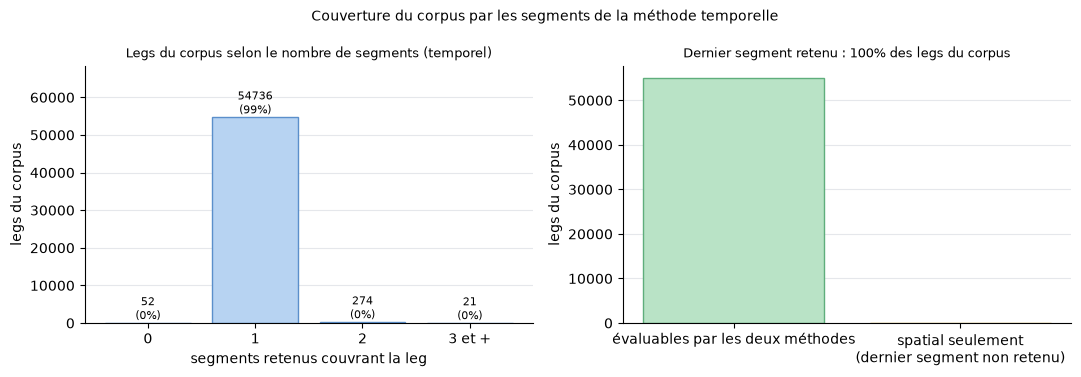

segments_kept
0       52
1    54736
2      274
3       21
Name: legs du corpus par nombre de segments retenus (3 = 3 et +), dtype: int64

In [16]:
per_leg = segments_per_leg(config, corpus)
fig = plot_segments_per_leg(per_leg)
fig.savefig(Path(config["_project_root"]) / OUTPUT_DIR / "figures" / "21_corpus_segments_per_leg.png", dpi=150)
display(fig)
plt.close(fig)
per_leg["segments_kept"].clip(upper=3).value_counts().sort_index().rename("legs du corpus par nombre de segments retenus (3 = 3 et +)")